# 05 — Reward and writing style: can the agent write like a person?

With the rewards of the README, the optimal agent **never lifts the pen**: it draws every letter in a
single stroke and goes back over segments already drawn (notebook 02). A person would rather lift the
pen. Here we study which reward produces which writing style.

## The trade-off

When the pen reaches the end of a stroke, the next stroke can be reached in two ways:

- **go back over** $k$ segments already drawn, pen down: cost $k\,(|r_\text{move}| + |r_\text{redrawn}|)$;
- **lift the pen**, make $m$ moves pen up and start a new stroke: cost $m\,|r_\text{move}| + |r_\text{stroke}|$.

The agent lifts the pen if and only if

$$m\,|r_\text{move}| + |r_\text{stroke}| \;<\; k\,\big(|r_\text{move}| + |r_\text{redrawn}|\big)$$

On a grid, the shortest pen-up path is often exactly as long as going back ($m = k$). With the README
rewards ($r_\text{redrawn} = 0$) the inequality becomes $|r_\text{stroke}| < 0$: **any** stroke penalty makes
going back better, and with no stroke penalty the two options cost exactly the same.

So we test two parameters:
1. the **stroke penalty** $r_\text{stroke}$ (README: −0.3);
2. a new **penalty for going back over a segment** $r_\text{redrawn}$ (README: 0, i.e. no penalty).

The optimal drawings are computed with **value iteration** (exact, notebook 02), then we check in
section 3 that an agent that **learns** (Q-learning) adopts the same style.

In [1]:
import sys
sys.path.insert(0, "..")

import csv
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image

from src.letters import TRAINING_LETTERS
from src.environment import LetterWritingEnv, Rewards
from src.dynamic_programming import value_iteration
from src.tabular_agents import q_learning
from src.evaluation import play_policy, greedy_policy
from src.visualization import plot_episodes, animate_episodes, SURFACE, TEXT, MUTED

GAMMA = 0.99
SETTINGS = {
    "README (stroke −0.3)": Rewards(),
    "stroke 0": Rewards(new_stroke=0.0),
    "stroke −0.1": Rewards(new_stroke=-0.1),
    "redrawn −0.1": Rewards(redrawn=-0.1),
    "redrawn −0.2": Rewards(redrawn=-0.2),
    "redrawn −0.5": Rewards(redrawn=-0.5),
}

## 1. Optimal drawings for each reward setting

Value iteration for the 10 letters and the 6 settings (the model must be rebuilt for each setting,
since the rewards change). For each letter, from its first natural starting point: number of strokes,
segments gone back over, moves with the pen up. **This cell takes about 2 minutes.**

In [2]:
optimal = {}   # optimal[setting][letter] = (env, policy, episode, mean v* over the starts)
t0 = time.perf_counter()
for label, rewards in SETTINGS.items():
    optimal[label] = {}
    for name in TRAINING_LETTERS:
        env = LetterWritingEnv(name, rewards=rewards)
        vi = value_iteration(env, gamma=GAMMA)
        ep = play_policy(env, vi["policy"], env.letter.start_points[0], gamma=GAMMA)
        v_mean = np.mean([vi["V"][s] for s in env.start_states()])
        optimal[label][name] = (env, vi["policy"], ep, v_mean)
    print(f"{label:<22} done ({time.perf_counter() - t0:.0f} s)")

rows = []
for metric, title in [("strokes", "strokes"), ("redrawn", "segments gone back over"), ("pen_up_moves", "pen-up moves")]:
    print(f"\n{title}")
    print(f"{'setting':<22}" + "".join(f"{n:>4}" for n in TRAINING_LETTERS))
    for label in SETTINGS:
        print(f"{label:<22}" + "".join(f"{optimal[label][n][2][metric]:>4}" for n in TRAINING_LETTERS))
for label in SETTINGS:
    for name in TRAINING_LETTERS:
        ep = optimal[label][name][2]
        rows.append({"setting": label, "letter": name, "strokes": ep["strokes"], "redrawn": ep["redrawn"],
                     "pen_up_moves": ep["pen_up_moves"], "steps": ep["steps"]})
with open("../results/05_style_table.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=rows[0].keys())
    writer.writeheader()
    writer.writerows(rows)
print("\nsaved: results/05_style_table.csv")

README (stroke −0.3)   done (17 s)
stroke 0               done (35 s)
stroke −0.1            done (56 s)
redrawn −0.1           done (73 s)
redrawn −0.2           done (94 s)
redrawn −0.5           done (116 s)

strokes
setting                  I   L   T   E   F   H   N   Z   V   X
README (stroke −0.3)     1   1   1   1   1   1   1   1   1   1
stroke 0                 3   1   2   2   2   3   1   1   1   3
stroke −0.1              1   1   1   1   1   1   1   1   1   1
redrawn −0.1             1   1   1   1   1   1   1   1   1   2
redrawn −0.2             1   1   2   2   2   3   1   1   1   2
redrawn −0.5             3   1   2   2   2   3   1   1   1   2

segments gone back over
setting                  I   L   T   E   F   H   N   Z   V   X
README (stroke −0.3)     2   0   2   2   2   4   0   0   0   4
stroke 0                 0   0   0   0   0   0   0   0   0   0
stroke −0.1              2   0   2   2   2   4   0   0   0   4
redrawn −0.1             2   0   2   2   2   4   0   0   0   0

### The drawings

Four settings (rows) on the letters whose style changes (columns). Dashed lines = moves with the pen up.

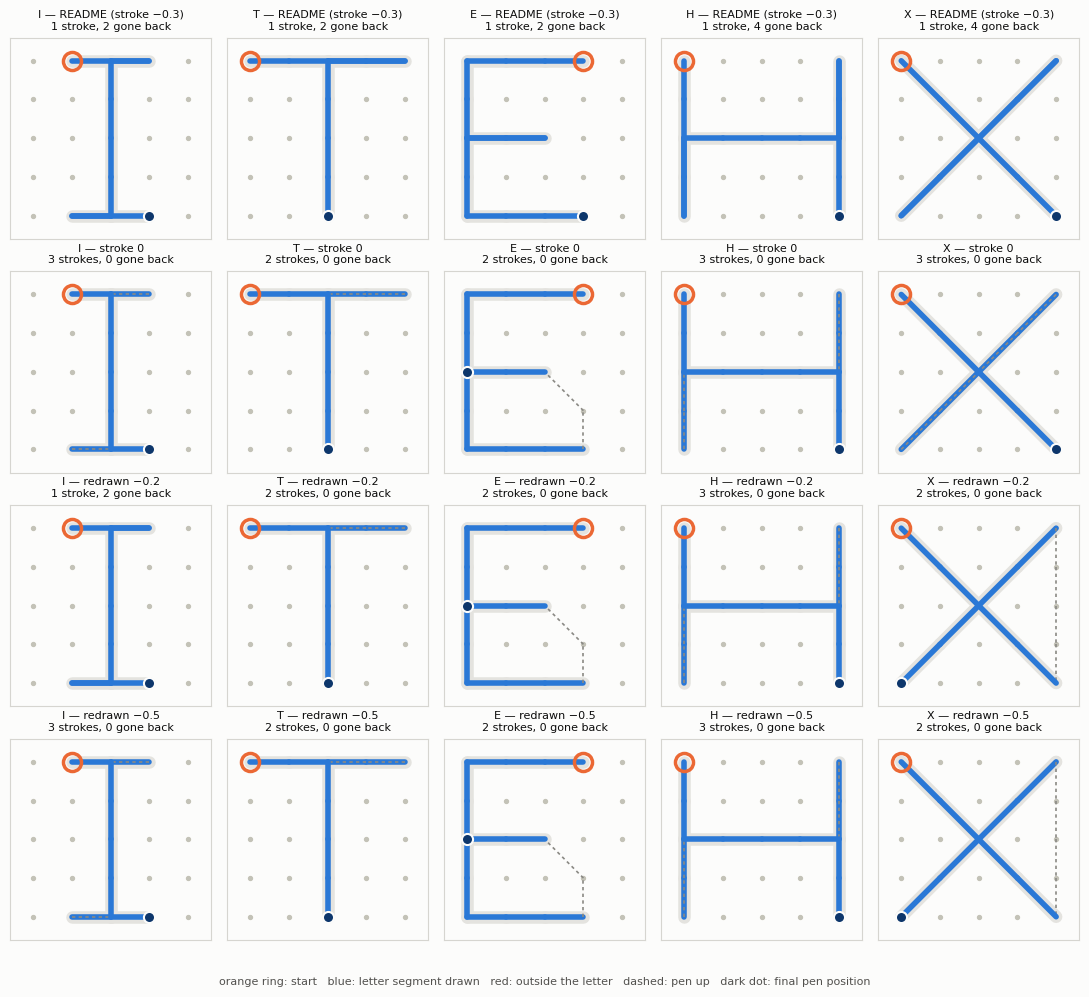

In [3]:
SHOW = ["README (stroke −0.3)", "stroke 0", "redrawn −0.2", "redrawn −0.5"]
LETTERS_SHOWN = ["I", "T", "E", "H", "X"]
panels = []
for label in SHOW:
    for name in LETTERS_SHOWN:
        env, _, ep, _ = optimal[label][name]
        panels.append((env.letter, ep["history"], f"{name} — {label}\n{ep['strokes']} stroke{'s' * (ep['strokes'] > 1)}, {ep['redrawn']} gone back"))
fig = plot_episodes(panels, ncols=5, path="../results/05_style_drawings.png")
for ax in fig.axes:
    ax.title.set_fontsize(8)
plt.show()

**About "stroke 0".** With no stroke penalty, going back and lifting the pen cost exactly the same
(when $m = k$): several policies are optimal. Value iteration keeps the first best action in the list, and
the pen-up actions come first (actions 0–7): this is why the agent lifts the pen. The style here is decided
by a tie, not by the reward. Increasing the stroke penalty (−0.1, −0.3, or more) always gives one single stroke.

## 2. The "human-like" setting: penalty −0.5 for going back

All 10 letters drawn by the optimal policy with $r_\text{redrawn} = -0.5$ (animation, saved for the presentation).

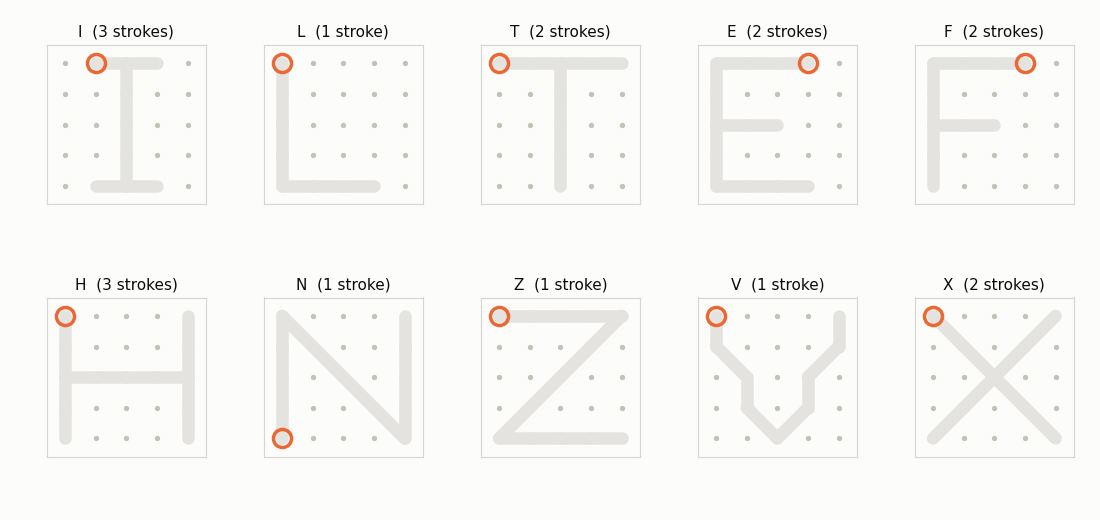

In [4]:
HUMAN = "redrawn −0.5"
panels_h = []
for name in TRAINING_LETTERS:
    env, _, ep, _ = optimal[HUMAN][name]
    panels_h.append((env.letter, ep["history"], f"{name}  ({ep['strokes']} stroke{'s' * (ep['strokes'] > 1)})"))
animate_episodes(panels_h, "../results/05_human_like_optimal.gif")
Image(filename="../results/05_human_like_optimal.gif")

## 3. Does a learning agent adopt the same style?

Value iteration gives the optimum. Does Q-learning, which only plays, also learn to lift the pen?
Q-learning with the human-like rewards, same parameters as notebook 03 (α = 0.5, 30,000 episodes),
one run per letter (seed 0). **This cell takes about 1 minute.**

letter   % of v*  perfect  strokes (Q)  strokes (optimal)  gone back (Q)
I            97%      yes            3                  3              0
L            97%      yes            1                  1              0
T           100%      yes            2                  2              0
E            98%      yes            2                  2              0
F            99%      yes            2                  2              0
H            97%      yes            3                  3              0
N           100%      yes            1                  1              0
Z           100%      yes            1                  1              0
V           100%      yes            1                  1              0
X            90%      yes            4                  2              0


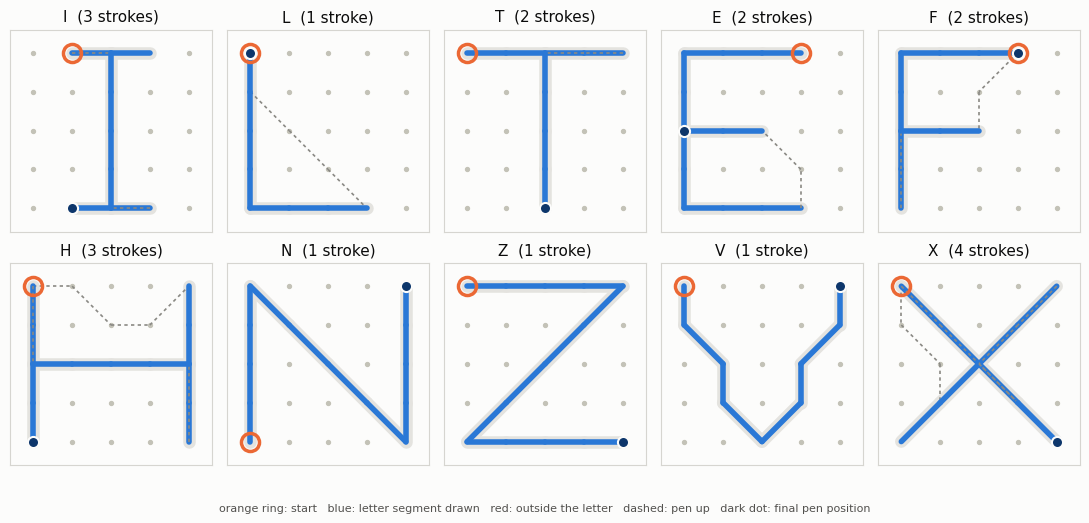

In [5]:
human_rewards = SETTINGS[HUMAN]
print(f"{'letter':<7}{'% of v*':>9}{'perfect':>9}{'strokes (Q)':>13}{'strokes (optimal)':>19}{'gone back (Q)':>15}")
panels_q = []
for name in TRAINING_LETTERS:
    env = LetterWritingEnv(name, rewards=human_rewards)
    res = q_learning(env, n_episodes=30_000, alpha=0.5, gamma=GAMMA, seed=0)
    policy = greedy_policy(res["Q"])
    ep = play_policy(env, policy, env.letter.start_points[0], gamma=GAMMA)
    _, _, ep_opt, v_mean = optimal[HUMAN][name]
    print(f"{name:<7}{100 * res['eval_return'][-1] / v_mean:>8.0f}%{'yes' if res['eval_perfect'][-1] == 1 else 'no':>9}"
          f"{ep['strokes']:>13}{ep_opt['strokes']:>19}{ep['redrawn']:>15}")
    panels_q.append((env.letter, ep["history"], f"{name}  ({ep['strokes']} stroke{'s' * (ep['strokes'] > 1)})"))

plot_episodes(panels_q, path="../results/05_human_like_q_learning.png")
plt.show()

## What to notice

(The numbers below come from our test run; yours should be identical for value iteration and very close for Q-learning.)

- **The stroke penalty alone cannot produce a human style.** With −0.1, −0.3 (README) or more, every letter is
  drawn in a single stroke, going back over 2 to 4 segments (I, T, E, F, H, X). With 0, lifting the pen and going
  back cost exactly the same: the strokes we see are decided by a tie, not by the reward. This is the trade-off
  inequality in action: with $r_\text{redrawn} = 0$ and $m = k$, lifting the pen can never be strictly better.
- **The penalty for going back is what changes the style**, and it does so letter by letter, exactly as the
  inequality predicts:
  - **−0.1**: only X switches to 2 strokes. Going back costs 4 × (0.05 + 0.1) = 0.6, lifting the pen
    4 × 0.05 + 0.3 = 0.5. For E, going back costs 2 × 0.15 = 0.3 < 0.4, so E stays in one stroke.
  - **−0.2**: T, E, F, H and X are drawn in several strokes; only I still goes back. At each junction of I the
    agent goes back over a single segment: 1 × (0.05 + 0.2) = 0.25, cheaper than lifting the pen
    (1 × 0.05 + 0.3 = 0.35).
  - **−0.5**: no segment is ever gone back over. I: 3 strokes, T, E, F, X: 2, H: 3, while L, N, Z, V stay in a
    single stroke — the number of strokes a person would use.
- **A learning agent adopts the same style.** Q-learning with the human-like rewards (−0.5) uses exactly the
  same number of strokes as the optimum for 9 letters out of 10, never goes back over a segment, draws every
  letter perfectly and reaches 97–100 % of the new optimum (X: 4 strokes instead of 2, 90 %).
- **For the discussion — reward design.** The reward does not only say *what* to do (draw the letter) but also
  *how* (the style). A behaviour we find natural (lifting the pen) appears only if the reward makes it strictly
  better; otherwise the agent exploits whatever is cheapest, even if it looks strange to us. Ng, Harada &
  Russell (1999) study exactly this question: which changes of the reward keep the optimal policy unchanged,
  and which ones change it.
